In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = '4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from utils.models import *
from utils.dataloader import *
from utils.utils_sig import *


모델 로드 완료
추론 완료: preds (122, 900), targets (122, 900)


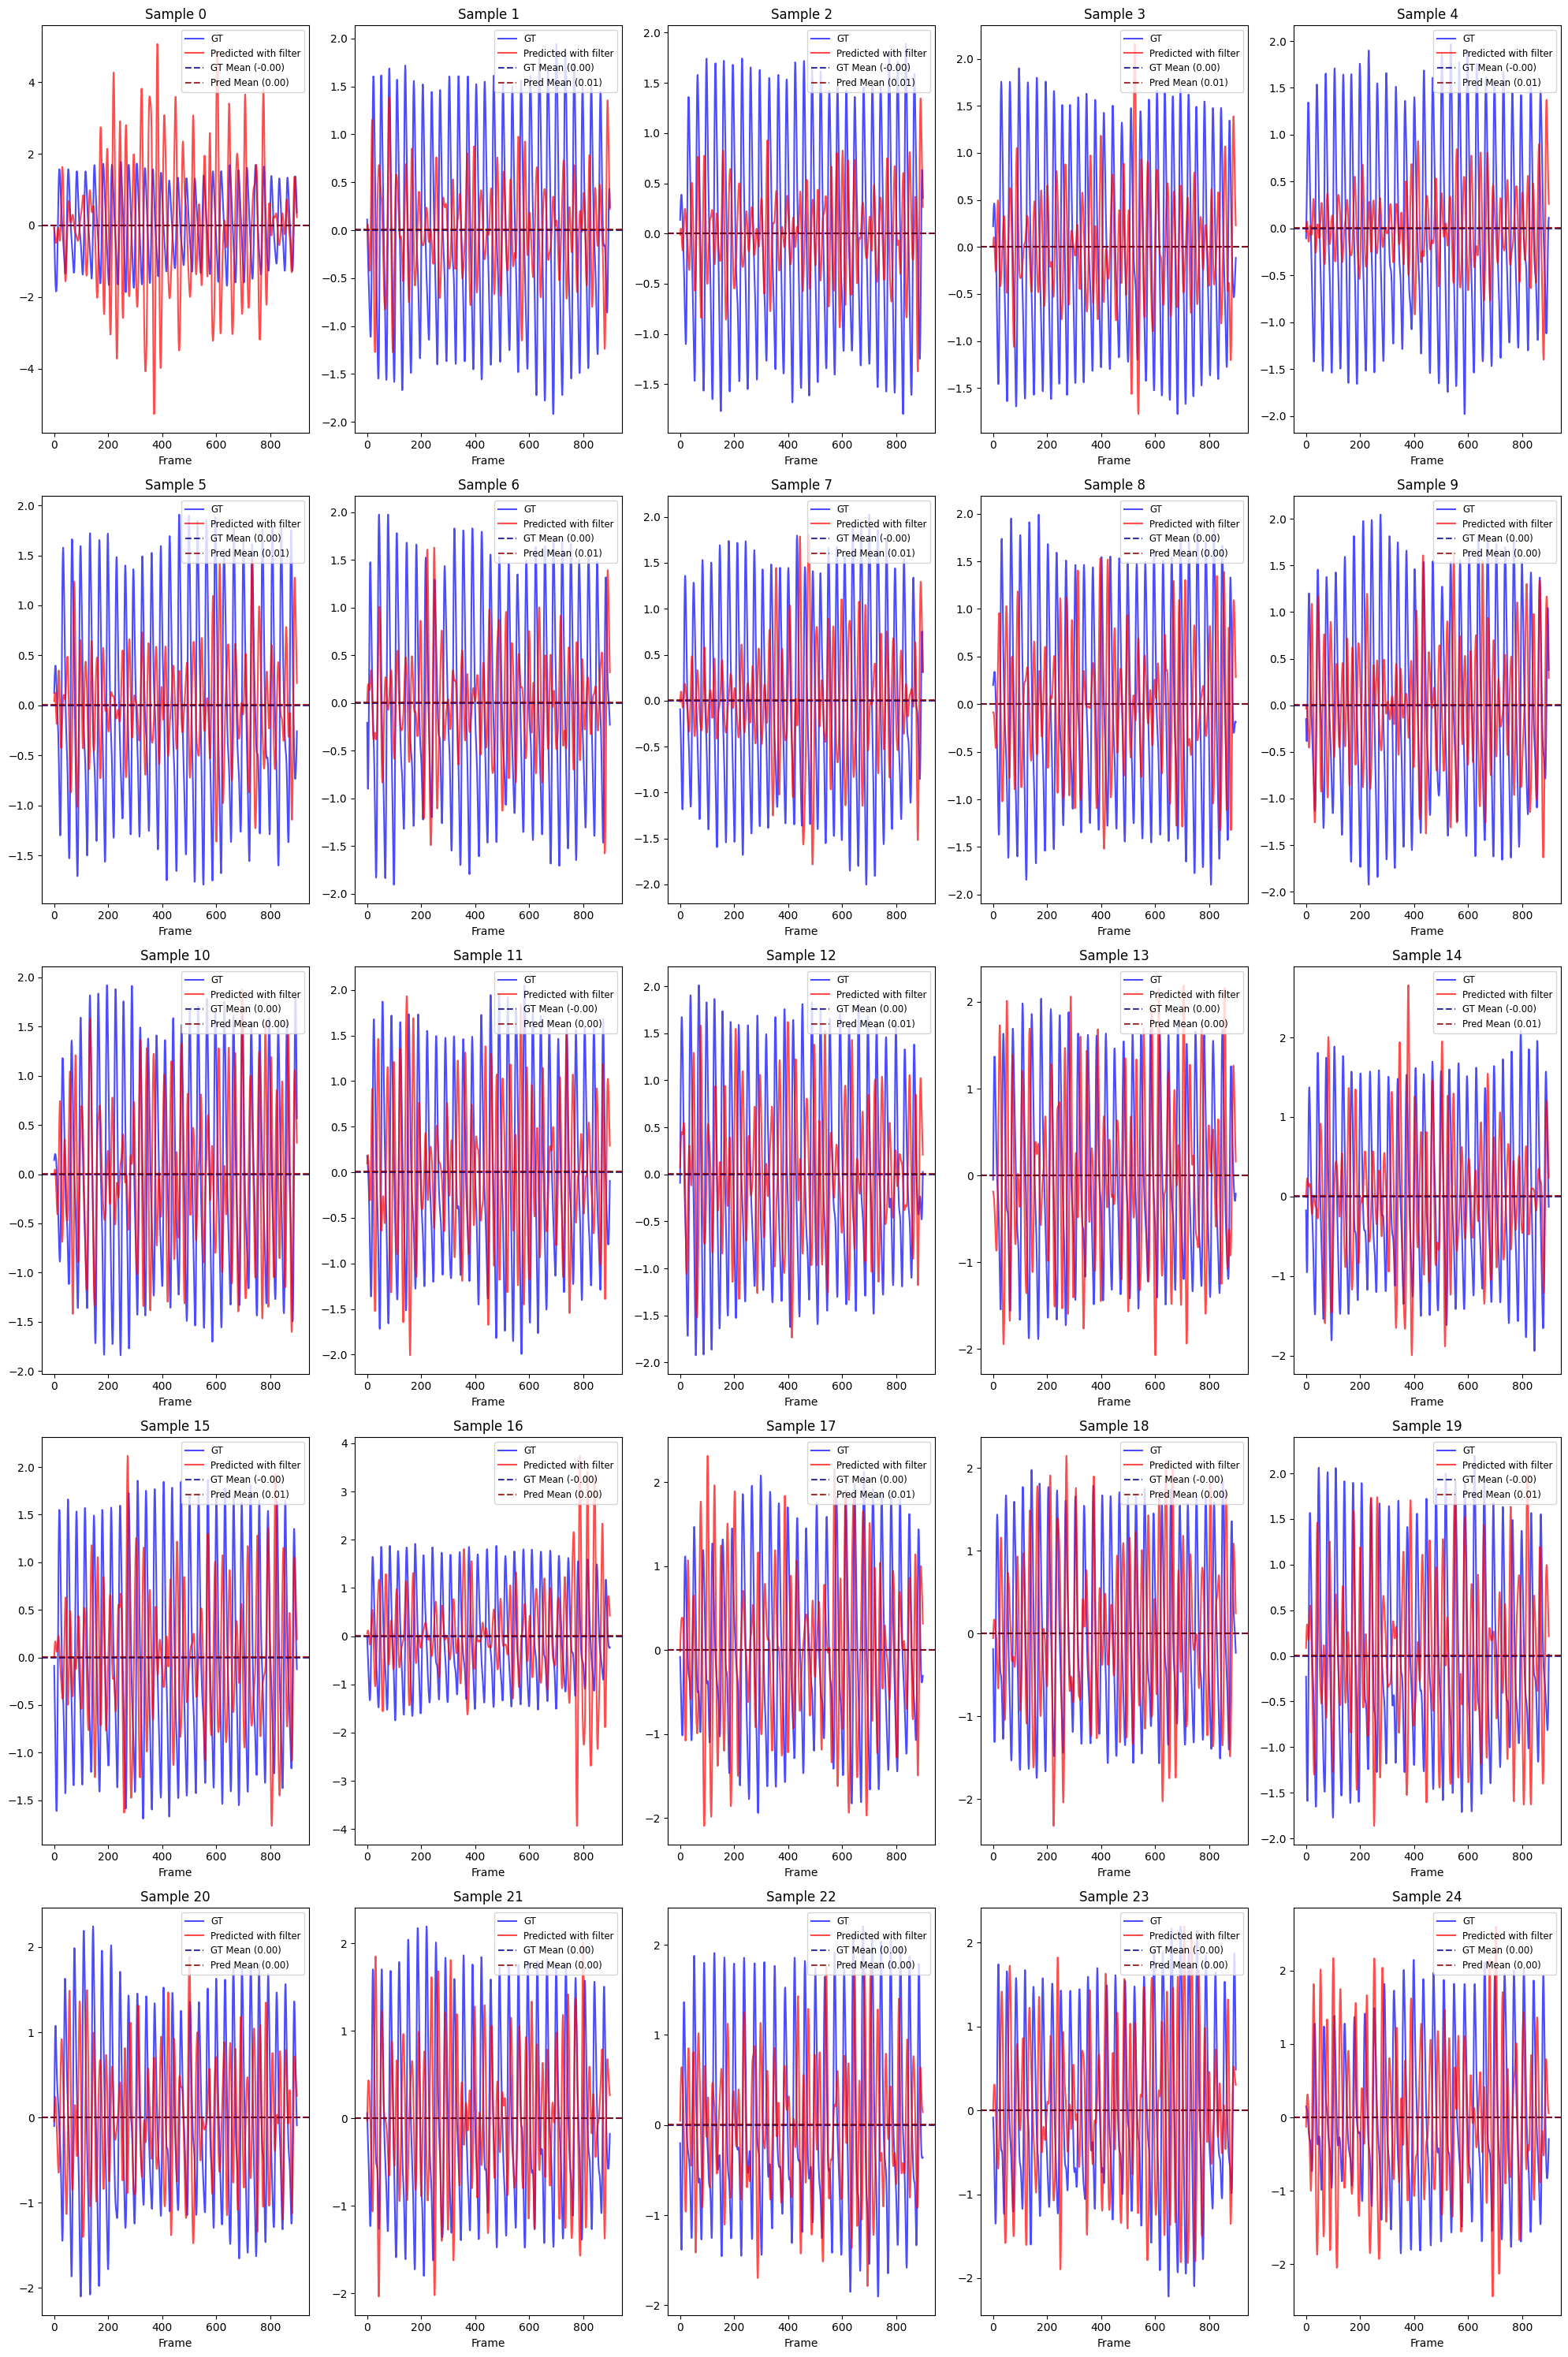

In [11]:
# ===== 설정 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/without13_and_normalization_ncorlossonly_test/physent_data_wo_ol_lr:0.00030000000000000003_epoch:41_MAE: 18.31.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_without_registration_cropped'
pic_save_dir ='/home/son/orientation-uv-rppg/data/pics'
# ===== 모델 로드 =====
model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")

# ===== 데이터 로드 =====
all_files = sorted([os.path.join(data_dir, f) for f in os.listdir(data_dir) if f.endswith('.h5')])
valid_files = all_files[13:14]
valid_dataset = rPPGDataset(valid_files)
valid_loader  = DataLoader(valid_dataset, batch_size=24, shuffle=False, num_workers=4)

# ===== 추론 =====
all_preds   = []
all_targets = []
all_preds_with_filter = []

with torch.no_grad():
    for inputs, targets in valid_loader:
        inputs  = inputs.to(device)
        outputs, _, _, _ = model(inputs)

        all_preds.append(outputs.cpu().numpy())
        all_targets.append(targets.numpy())

all_preds   = np.concatenate(all_preds,   axis=0)  # (N, 300)
all_targets = np.concatenate(all_targets, axis=0)  # (N, 300)

for i in range(len(all_preds)) :
    all_preds_with_filter.append(butter_bandpass_filter(all_preds[i], 0.66, 2.5, 30))

print(f"추론 완료: preds {all_preds.shape}, targets {all_targets.shape}")

# ===== Plot =====
n_plot = 25  # 몇 개 샘플 볼지
fig, axes = plt.subplots(5, 5, figsize=(20, 30))
axes = axes.flatten()

for i in range(n_plot):
    # 코드가 길어지는 것을 방지하기 위해 변수에 할당
    gt_sig = all_targets[i]
    pred_sig =  all_preds_with_filter[i] 

    # 신호 그리기
    axes[i].plot(gt_sig, label='GT', color='blue', alpha=0.7)
    axes[i].plot(pred_sig, label='Predicted with filter', color='red', alpha=0.7)
    
    # --- 💡 평균값 계산 및 수평선 그리기 추가 💡 ---
    gt_mean = np.mean(gt_sig)
    pred_mean = np.mean(pred_sig)
    
    axes[i].axhline(y=gt_mean, color='darkblue', linestyle='--', alpha=0.8, 
                    label=f'GT Mean ({gt_mean:.2f})')
    axes[i].axhline(y=pred_mean, color='darkred', linestyle='--', alpha=0.8, 
                    label=f'Pred Mean ({pred_mean:.2f})')
    # ---------------------------------------------

    #axes[i].plot(10*all_preds[i],   label='Predicted', color='green',   alpha=0.7)
    #axes[i].set_ylim(-2,2)
    #axes[i].set_xlim(0,300)    
    axes[i].set_title(f'Sample {i}')
    
    # 범례가 많아지므로 폰트 크기를 살짝 줄이거나 위치를 조정하는 것도 좋습니다.
    axes[i].legend(loc='upper right', fontsize='small') 
    axes[i].set_xlabel('Frame')


plt.tight_layout()
#plt.savefig(os.path.join(pic_save_dir, 'withoutt13_nonormalize_timedomain'), dpi= 100)
plt.show()



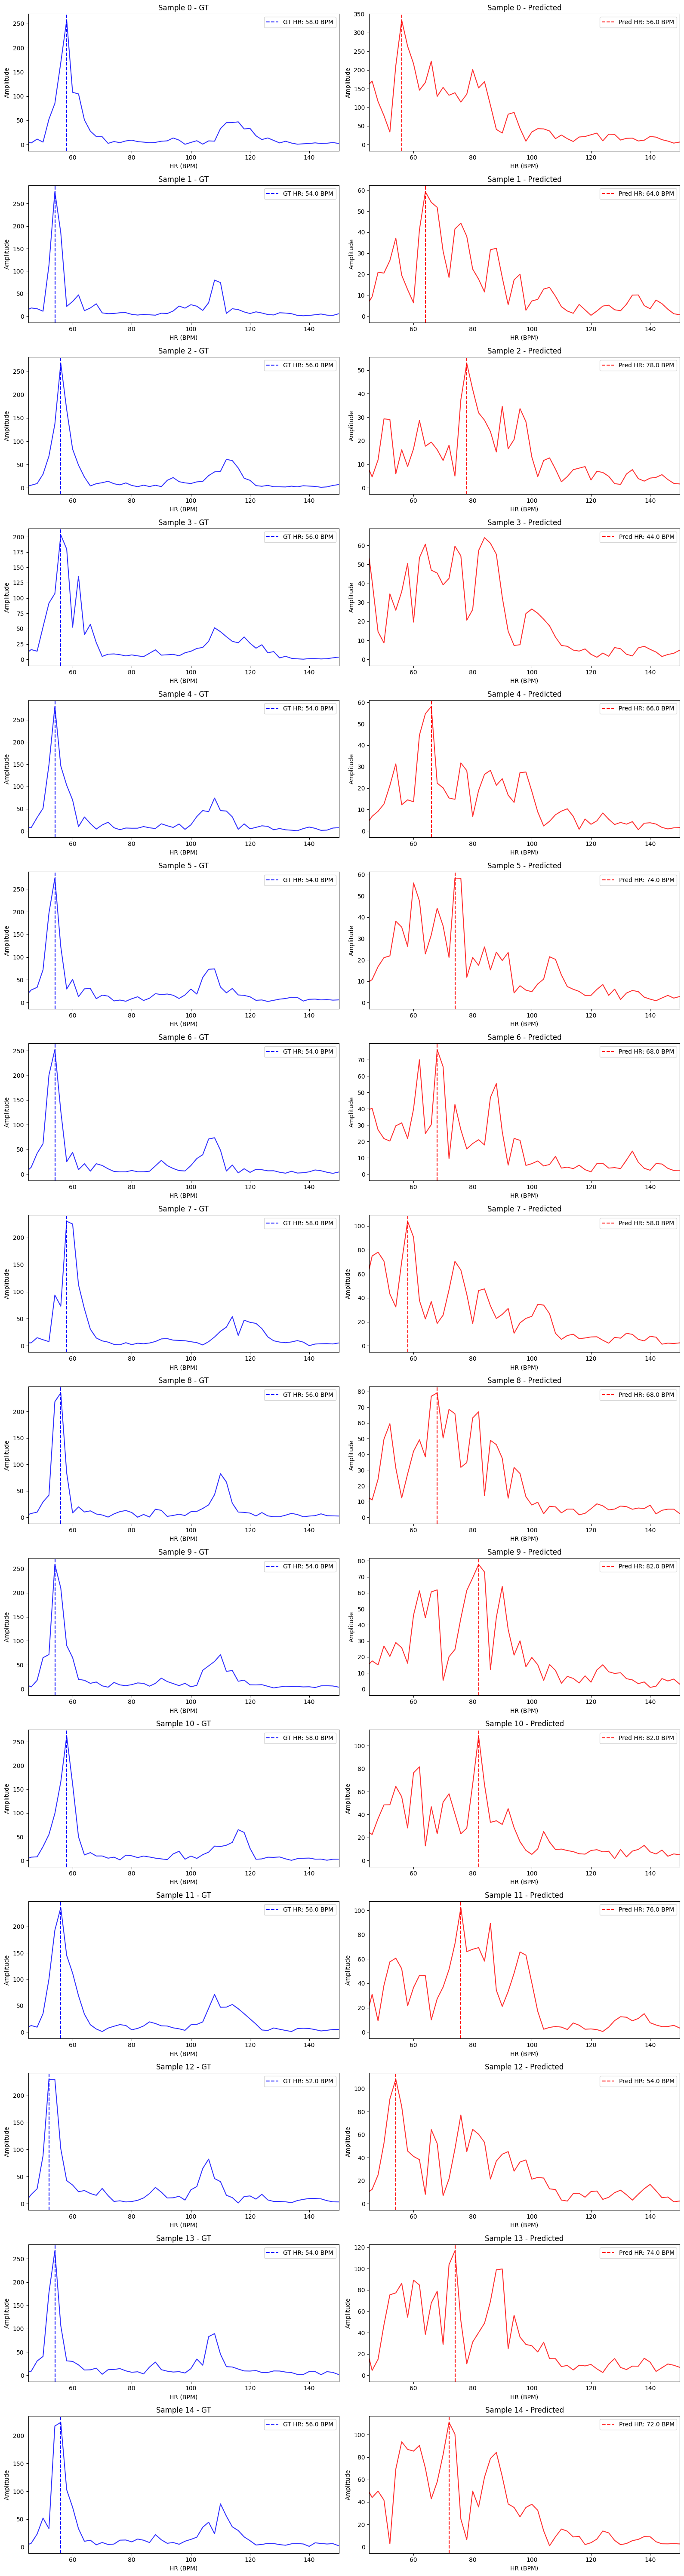

저장완료: fft_comparison.png


<Figure size 640x480 with 0 Axes>

In [12]:
from scipy.fft import fft

n_plot = 15
fig, axes = plt.subplots(n_plot, 2, figsize=(16, 4*n_plot))

for i in range(n_plot):
    pred_sig = all_preds_with_filter[i]
    gt_sig   = all_targets[i]

    hr_pred, psd_pred, x_hr_pred = hr_fft(pred_sig, fs=30)
    hr_gt,   psd_gt,   x_hr_gt   = hr_fft(gt_sig,   fs=30)

    # GT PSD
    axes[i, 0].plot(x_hr_gt, psd_gt, color='blue', alpha=0.8)
    axes[i, 0].axvline(hr_gt,   color='blue',  linestyle='--', label=f'GT HR: {hr_gt:.1f} BPM')
    axes[i, 0].set_xlim(0.75*60, 2.5*60)
    axes[i, 0].set_title(f'Sample {i} - GT')
    axes[i, 0].set_xlabel('HR (BPM)')
    axes[i, 0].set_ylabel('Amplitude')
    axes[i, 0].legend()

    # Pred PSD
    axes[i, 1].plot(x_hr_pred, psd_pred, color='red', alpha=0.8)
    axes[i, 1].axvline(hr_pred, color='red',   linestyle='--', label=f'Pred HR: {hr_pred:.1f} BPM')
    axes[i, 1].set_xlim(0.75*60, 2.5*60)
    axes[i, 1].set_title(f'Sample {i} - Predicted')
    axes[i, 1].set_xlabel('HR (BPM)')
    axes[i, 1].set_ylabel('Amplitude')
    axes[i, 1].legend()

plt.tight_layout()

plt.show()
plt.savefig(os.path.join(pic_save_dir, 'nirp_uv_valid_frequencydomain'), dpi= 100)
print("저장완료: fft_comparison.png")